
Determine how many of the admission types without a discharge location are observational and not an actual in-patient admission. This helps decide if we are going to exlcude records without discharge locations.



In [1]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
SELECT admission_type, COUNT(*) AS n
FROM `physionet-data.mimiciv_3_1_hosp.admissions`
-- if no discharge location AND they survived hospital stay
WHERE discharge_location IS NULL AND hospital_expire_flag = 0
GROUP BY admission_type
ORDER BY n DESC;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,admission_type,n
0,EU OBSERVATION,118123
1,DIRECT OBSERVATION,23781
2,AMBULATORY OBSERVATION,7099
3,EW EMER.,273
4,OBSERVATION ADMIT,152
5,SURGICAL SAME DAY ADMISSION,87
6,URGENT,70
7,DIRECT EMER.,56
8,ELECTIVE,15


We find that majority of the admissions without discharge locations are observational admissions and not in-patient admission, so we exclude these. Filter the MIMIC-IV dataset according to our inclusion/exclusion criteria.

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
CREATE OR REPLACE TABLE `mimic-iv-512404.analysis.readmission_records` AS
WITH base AS (
  SELECT
    a.subject_id, a.hadm_id, g.age, p.gender,
    a.admittime, a.dischtime, a.admission_type,
    a.admission_location, a.discharge_location,
    a.insurance, a.language, a.marital_status, a.race,
    a.hospital_expire_flag, -- if patient dies, exclude
    -- unplanned admission, skips over planned admissions until end of rows
    MIN(CASE WHEN a.admission_type NOT IN ('ELECTIVE','SURGICAL SAME DAY ADMISSION')
             THEN a.admittime END) OVER (
      PARTITION BY a.subject_id
      ORDER BY a.admittime
      ROWS BETWEEN 1 FOLLOWING AND UNBOUNDED FOLLOWING
    ) AS next_unplanned_admittime,
    -- counting prior admissions per patient
    COUNT(*) OVER (
      PARTITION BY a.subject_id
      ORDER BY a.admittime
      ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING
    ) AS n_prior_admissions
  FROM `physionet-data.mimiciv_3_1_hosp.admissions` a
  JOIN `physionet-data.mimiciv_3_1_derived.age` g
    ON a.subject_id = g.subject_id AND a.hadm_id = g.hadm_id
  JOIN `physionet-data.mimiciv_3_1_hosp.patients` p
    ON a.subject_id = p.subject_id
)
-- calculate how long between visits
SELECT
  *,
  DATETIME_DIFF(dischtime, admittime, HOUR) / 24.0 AS los_days,
  IF(DATETIME_DIFF(next_unplanned_admittime, dischtime, DAY) BETWEEN 1 AND 30, 1, 0) AS readmit_30d
FROM base
-- inclusion criteria
WHERE age >= 18
  AND hospital_expire_flag = 0
  AND discharge_location != 'AGAINST ADVICE'
  AND discharge_location IS NOT NULL;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,CREATE_TABLE_AS_SELECT,job_fN2AGrcGLapknnF9azHMqX8hFQHS,US


Determine if the patient has gone to the ICU and how many times.

In [2]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- from readmission_records, determine icu data
SELECT
  c.*,
  IF(icu.hadm_id IS NULL, 0, 1) AS had_icu,
  COALESCE(icu.n_icu_stays, 0) AS n_icu_stays,
  COALESCE(icu.icu_los_days, 0) AS icu_los_days,
  COALESCE(icu.first_careunit, 'NO ICU') AS first_careunit
FROM `mimic-iv-512404.analysis.readmission_records` c
-- attach icu info even if admission had no icu stay
LEFT JOIN (
  -- summarize icu stay to one row per admission
  SELECT
    hadm_id,
    COUNT(*) AS n_icu_stays,
    SUM(los) AS icu_los_days,
    ARRAY_AGG(first_careunit ORDER BY intime LIMIT 1)[OFFSET(0)] AS first_careunit
  FROM `physionet-data.mimiciv_3_1_icu.icustays`
  GROUP BY hadm_id
) icu
  ON c.hadm_id = icu.hadm_id; -- keeps both types of admissions, with or without icu stay
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,subject_id,hadm_id,age,gender,admittime,dischtime,admission_type,admission_location,discharge_location,insurance,...,race,hospital_expire_flag,next_unplanned_admittime,n_prior_admissions,los_days,readmit_30d,had_icu,n_icu_stays,icu_los_days,first_careunit
0,15880421,20630262,87,F,2184-05-19 01:51:00,2184-05-19 14:30:00,EW EMER.,EMERGENCY ROOM,HOME,Medicare,...,WHITE,0,<NA>,0,0.541667,0,0,0,0.0,NO ICU
1,18003109,26886609,87,M,2155-04-08 03:21:00,2155-04-19 19:41:00,EW EMER.,EMERGENCY ROOM,SKILLED NURSING FACILITY,Medicare,...,WHITE,0,<NA>,0,11.666667,0,0,0,0.0,NO ICU
2,18751336,22286972,87,F,2197-11-26 16:35:00,2197-11-27 17:28:00,EW EMER.,EMERGENCY ROOM,HOME HEALTH CARE,Medicare,...,HISPANIC/LATINO - DOMINICAN,0,2197-12-23 14:27:00,1,1.041667,1,0,0,0.0,NO ICU
3,18057532,21037604,87,M,2179-02-25 15:11:00,2179-03-04 21:33:00,EW EMER.,EMERGENCY ROOM,HOME,Medicaid,...,HISPANIC OR LATINO,0,2179-08-08 22:07:00,5,7.25,0,0,0,0.0,NO ICU
4,10345346,29079135,87,F,2170-02-07 19:28:00,2170-02-15 18:10:00,EW EMER.,EMERGENCY ROOM,CHRONIC/LONG TERM ACUTE CARE,Medicare,...,BLACK/AFRICAN AMERICAN,0,2170-02-28 18:55:00,1,7.958333,1,0,0,0.0,NO ICU
5,13517478,29627399,87,F,2134-02-05 02:05:00,2134-02-25 18:00:00,EW EMER.,EMERGENCY ROOM,SKILLED NURSING FACILITY,Medicare,...,WHITE,0,<NA>,3,20.666667,0,1,1,1.629421,Medical/Surgical Intensive Care Unit (MICU/SICU)
6,14849280,27514994,87,F,2154-01-21 21:36:00,2154-01-30 13:58:00,EW EMER.,EMERGENCY ROOM,SKILLED NURSING FACILITY,Medicare,...,WHITE,0,2154-02-01 20:54:00,7,8.666667,1,0,0,0.0,NO ICU
7,12860576,26952258,87,F,2169-02-26 16:28:00,2169-03-03 15:45:00,EW EMER.,EMERGENCY ROOM,HOME,Medicare,...,WHITE,0,2173-12-09 00:48:00,2,4.958333,0,0,0,0.0,NO ICU
8,19273791,25340199,87,M,2160-11-24 17:09:00,2160-11-29 15:40:00,EW EMER.,EMERGENCY ROOM,REHAB,Medicare,...,WHITE,0,2160-12-17 00:15:00,1,4.916667,1,0,0,0.0,NO ICU
9,13582252,22611399,87,M,2166-01-01 11:03:00,2166-01-04 13:50:00,EW EMER.,EMERGENCY ROOM,HOME HEALTH CARE,Medicare,...,WHITE,0,<NA>,1,3.083333,0,1,1,1.401806,Medical/Surgical Intensive Care Unit (MICU/SICU)


Determine how many records are removed after each exclusion step.

In [3]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- how many admissions remain after each filter
-- and how many each filter removed
CREATE OR REPLACE TABLE `mimic-iv-512404.analysis.exclusion_table` AS
-- admissions with no age record are kept and can be counted as excluded
WITH joined AS (
  SELECT
    a.subject_id, a.hadm_id, g.age,
    a.hospital_expire_flag, a.discharge_location
  FROM `physionet-data.mimiciv_3_1_hosp.admissions` a
  LEFT JOIN `physionet-data.mimiciv_3_1_derived.age` g
    ON a.subject_id = g.subject_id AND a.hadm_id = g.hadm_id
),
-- count admissions left after each filter, applied cumulatively
counts AS (
  SELECT
    COUNT(*) AS s0,
    COUNTIF(age IS NOT NULL) AS s1,
    COUNTIF(age IS NOT NULL AND age >= 18) AS s2,
    COUNTIF(age >= 18 AND hospital_expire_flag = 0) AS s3,
    COUNTIF(age >= 18 AND hospital_expire_flag = 0
            AND discharge_location IS NOT NULL) AS s4,
    COUNTIF(age >= 18 AND hospital_expire_flag = 0
            AND discharge_location IS NOT NULL
            AND discharge_location != 'AGAINST ADVICE') AS s5
  FROM joined
),
-- one row per step of filtering
steps AS (
  SELECT 0 AS step, 'All admissions' AS description, s0 AS remaining FROM counts UNION ALL
  SELECT 1, 'Has an age record (join to derived.age)', s1 FROM counts UNION ALL
  SELECT 2, 'Adult (age >= 18)', s2 FROM counts UNION ALL
  SELECT 3, 'Survived the stay (hospital_expire_flag = 0)', s3 FROM counts UNION ALL
  SELECT 4, 'Discharge location not missing', s4 FROM counts UNION ALL
  SELECT 5, 'Not discharged against medical advice', s5 FROM counts
)
-- put into table as step, description, remaining, and excluded
SELECT
  step,
  description,
  remaining,
  LAG(remaining) OVER (ORDER BY step) - remaining AS excluded
FROM steps
ORDER BY step;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,CREATE_TABLE_AS_SELECT,job_8CxiGLY8f7xn_w4AbLxAJfv-3zBb,US


Find the admission records that have a 30-day or less readmission.

In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- determining how many of the records have 30-day readmissions
SELECT readmit_30d, COUNT(*) AS n,
       ROUND(COUNT(*) / SUM(COUNT(*)) OVER (), 3) AS proportion
FROM `mimic-iv-512404.analysis.readmission_records_icu`
GROUP BY readmit_30d;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,readmit_30d,n,proportion
0,0,310560,0.815
1,1,70618,0.185


In [ ]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
-- creating the table where 30 day readmission with icu data
CREATE OR REPLACE TABLE `mimic-iv-512404.analysis.30d_readmitted_only` AS
SELECT *
FROM `mimic-iv-512404.analysis.readmission_records_icu`
WHERE readmit_30d = 1;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,statement_type,job_id,location
0,CREATE_TABLE_AS_SELECT,job_ast88mMdCPO4COXE2xRmWFXbE9L9,US


Determine among the 30-day and non 30-day admissions, how many unique patients are there.

In [4]:
# sql_engine: bigquery
# output_variable: df
# output_mode: table
# start _sql
_sql = """
SELECT readmit_30d,
       COUNT(*) AS n_admissions,
       COUNT(DISTINCT subject_id) AS n_patients -- unique n of patients
FROM `mimic-iv-512404.analysis.readmission_records_icu`
GROUP BY readmit_30d;
""" # end _sql
from google.colab.sql import bigquery as _bqsqlcell
df = _bqsqlcell.run(_sql)
df

,readmit_30d,n_admissions,n_patients
0,0,310560,170198
1,1,70618,35863


Determine the demographics of the 30-day readmission population.

In [ ]:
!pip install tableone openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.0 MB/s eta 0:00:00


In [ ]:
import pandas as pd
from tableone import TableOne

# collapse race into a few groups
def race_group(r):
    r = str(r).upper()
    if r.startswith("WHITE"): return "White"
    if r.startswith("BLACK"): return "Black"
    if r.startswith("HISPANIC"): return "Hispanic/Latino"
    if r.startswith("ASIAN"): return "Asian"
    return "Other/Unknown"

df = pd.read_gbq(
    "SELECT * FROM `mimic-iv-512404.analysis.readmission_records_icu`",
    project_id="mimic-iv-512404",
)

# make copy and keep original untouched
t1_df = df.copy()

# making the table with groups
t1_df["race_group"] = t1_df["race"].apply(race_group)
t1_df["age_group"] = pd.cut(t1_df["age"], [17, 39, 59, 74, 120],
                            labels = ["18-39", "40-59", "60-74", "75+"])
t1_df["readmit_30d"] = t1_df["readmit_30d"].map({0: "Not readmitted", 1: "Readmitted"})

columns = ["age", "age_group", "gender", "race_group", "insurance", "language",
           "marital_status", "admission_type", "discharge_location",
           "los_days", "n_prior_admissions", "had_icu", "icu_los_days"]
categorical = ["age_group", "gender", "race_group", "insurance", "language",
               "marital_status", "admission_type", "discharge_location", "had_icu"]
nonnormal = ["los_days", "n_prior_admissions", "icu_los_days"]  # median IQR

t1 = TableOne(t1_df, columns = columns, categorical = categorical,
              groupby = "readmit_30d", nonnormal = nonnormal,
              pval = False, smd = True, missing = True)

# write to excel file
t1.to_excel("demo_tbl.xlsx")

/tmp/ipykernel_105/4082280949.py:13: FutureWarning: read_gbq is deprecated and will be removed in a future version. Please use pandas_gbq.read_gbq instead: https://pandas-gbq.readthedocs.io/en/latest/api.html#pandas_gbq.read_gbq
  df = pd.read_gbq(


After getting baseline demographics and clinical statistics, we need to run XGBoost for AUROC and PRAUC.

In [ ]:
import xgboost as xgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

cat_cols = ["admission_type", "admission_location", "discharge_location",
            "insurance", "language", "marital_status", "race", "gender",
            "first_careunit"]
num_cols = ["age", "los_days", "n_prior_admissions",
            "had_icu", "n_icu_stays", "icu_los_days"]

# fill with category
for c in cat_cols:
    df[c] = df[c].fillna("UNKNOWN").astype("category")

X = df[cat_cols + num_cols] # independent var
y = df["readmit_30d"].astype(int) # dependent var - 30d readmission

aucs, aps = [], []

# split/train
# 5 fold cross validation
for tr, te in GroupKFold(n_splits = 5).split(X, y, groups = df["subject_id"]):
    m = xgb.XGBClassifier(
        n_estimators = 400, learning_rate = 0.05, max_depth = 5,
        tree_method = "hist", enable_categorical = True, eval_metric = "logloss",
    )
    m.fit(X.iloc[tr], y.iloc[tr])
    p = m.predict_proba(X.iloc[te])[:, 1]
    aucs.append(roc_auc_score(y.iloc[te], p))
    aps.append(average_precision_score(y.iloc[te], p))

# avg of the split/train
print("AUROC:", sum(aucs)/5, "AUPRC:", sum(aps)/5)

AUROC: 0.6991006679263941 AUPRC: 0.3388902536498509


We need to compare the model to a logistic regression.

In [ ]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_validate

# median imputation
pre = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy = "median", add_indicator = True)),
        ("scale", StandardScaler()),
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown = "ignore", min_frequency = 50), cat_cols),
])

# log reg model
logit = Pipeline([
    ("pre", pre),
    ("model", LogisticRegression(max_iter = 2000)),
])

# 5 fold validation
res = cross_validate(
    logit, X, y,
    cv = GroupKFold(n_splits = 5),
    groups = df["subject_id"],
    scoring = ["roc_auc", "average_precision"],
)

# avg
print("Logistic AUROC:", res["test_roc_auc"].mean(), "SD:", res["test_roc_auc"].std())
print("Logistic AUPRC:", res["test_average_precision"].mean(), "SD:", res["test_average_precision"].std())

Logistic AUROC: 0.6739409499154987 SD: 0.001247931558291373
Logistic AUPRC: 0.31732040463783046 SD: 0.003131930396998286


Plot the AUCs: XGBoost v. logistic regression

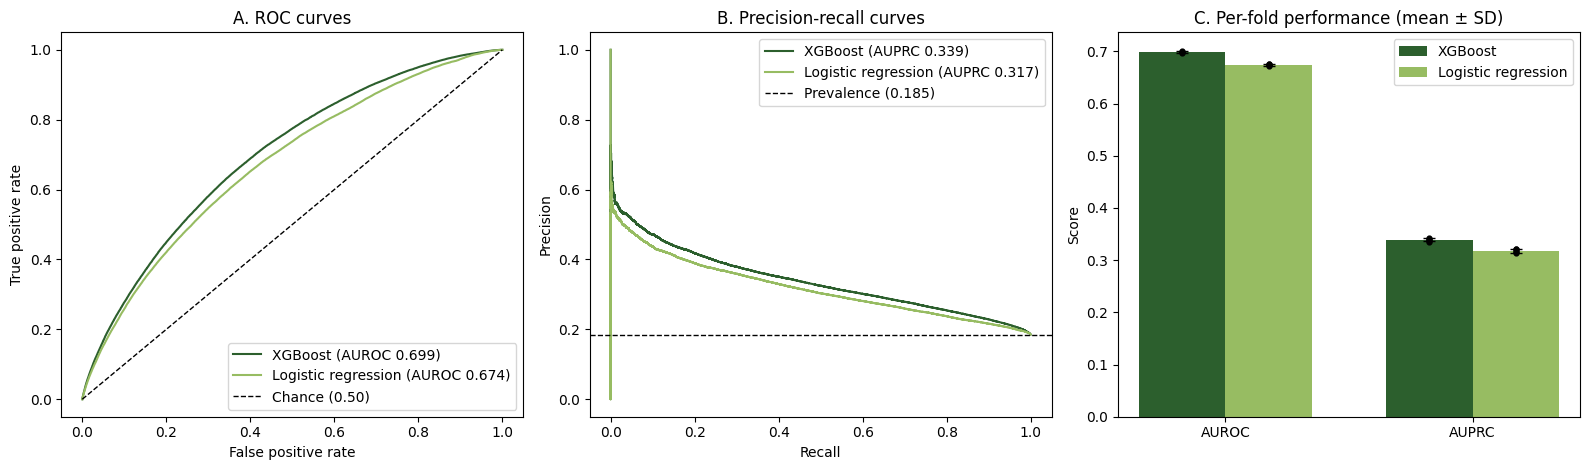

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_curve, precision_recall_curve,
                             roc_auc_score, average_precision_score)

# establish xgboost model
xgb_model = xgb.XGBClassifier(
    n_estimators = 400, learning_rate = 0.05, max_depth = 5,
    tree_method = "hist", enable_categorical = True, eval_metric = "logloss",
)

# compare the models
p_xgb = np.zeros(len(y))
p_lr = np.zeros(len(y))
fold = {"xgb_auc": [], "lr_auc": [], "xgb_ap": [], "lr_ap": []}

# fair model replication
for tr, te in GroupKFold(n_splits = 5).split(X, y, groups = df["subject_id"]):
    mx = clone(xgb_model).fit(X.iloc[tr], y.iloc[tr])
    ml = clone(logit).fit(X.iloc[tr], y.iloc[tr])
    p_xgb[te] = mx.predict_proba(X.iloc[te])[:, 1]
    p_lr[te] = ml.predict_proba(X.iloc[te])[:, 1]
    yt = y.iloc[te]
    # per-fold
    fold["xgb_auc"].append(roc_auc_score(yt, p_xgb[te]))
    fold["lr_auc"].append(roc_auc_score(yt, p_lr[te]))
    fold["xgb_ap"].append(average_precision_score(yt, p_xgb[te]))
    fold["lr_ap"].append(average_precision_score(yt, p_lr[te]))

prev = y.mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))

# figure a: roc
for p, name, key, c in [(p_xgb, "XGBoost", "xgb_auc", "#2C5F2D"),
                        (p_lr, "Logistic regression", "lr_auc", "#97BC62")]:
    fpr, tpr, _ = roc_curve(y, p)
    ax[0].plot(fpr, tpr, color=c,
               label=f"{name} (AUROC {np.mean(fold[key]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw = 1, label = "Chance (0.50)")
ax[0].set(xlabel = "False positive rate", ylabel = "True positive rate", title = "A. ROC curves")
ax[0].legend(loc = "lower right")

# figure b: precision recall
for p, name, key, c in [(p_xgb, "XGBoost", "xgb_ap", "#2C5F2D"),
                        (p_lr, "Logistic regression", "lr_ap", "#97BC62")]:
    pr, rc, _ = precision_recall_curve(y, p)
    ax[1].plot(rc, pr, color = c, label = f"{name} (AUPRC {np.mean(fold[key]):.3f})")
ax[1].axhline(prev, color = "k", ls="--", lw = 1, label = f"Prevalence ({prev:.3f})")
ax[1].set(xlabel = "Recall", ylabel = "Precision", title = "B. Precision-recall curves")
ax[1].legend(loc = "upper right")

# figure c: per-fold auroc and auprc
x = np.arange(2)
for i, (name, k, c) in enumerate([("XGBoost", "xgb", "#2C5F2D"),
                                  ("Logistic regression", "lr", "#97BC62")]):
    means = [np.mean(fold[f"{k}_auc"]), np.mean(fold[f"{k}_ap"])]
    sds = [np.std(fold[f"{k}_auc"]), np.std(fold[f"{k}_ap"])]
    ax[2].bar(x + (i - 0.5) * 0.35, means, 0.35, yerr = sds, capsize = 4, color = c, label = name)
    for j, key in enumerate(["auc", "ap"]):
        ax[2].scatter(np.full(5, x[j] + (i - 0.5) * 0.35), fold[f"{k}_{key}"],
                      color = "k", s = 12, zorder = 3)
ax[2].set_xticks(x); ax[2].set_xticklabels(["AUROC", "AUPRC"])
ax[2].set(ylabel = "Score", title = "C. Per-fold performance (mean ± SD)")
ax[2].legend()

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()